# Nural Network hands on

Problem background : A buisness is loosing customers at alarming rate, we have to predict weather a customer is going to cancle their service in next month given the dataset which we have.
Due to potential saving chances of 60% if retention campain is able to target correct costumers.
Approach : Binary classification problem with implementing simple nural network to find deep pattern with given problem set.

### <center> Learning objectives </center>
1. Analyze real world dataset
2. Handle imbalance dataset
3. Build and tune nural network for binary classification
4. Evaluate Model using buisness related matrices
5. Design production ready ML model

In [412]:
# Loading dataset
import pandas as pd
path = '/home/madhav/workstation/Lab/DataSet/telco-curn.csv'

df = pd.read_csv(path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [413]:
# Read the documentation about each import requirements and their implementation
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau  # auto lowers learning rate

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix # tools for evaluating training model
import torch.optim as optim  # optimizers live inside adm | variant of mini batch gradient descent algorithm

TotalCustomers  ChurnedCustomers  ChurnRate
PaymentMethod                                                         
Electronic check                     2365              1071   0.452854
Mailed check                         1612               308   0.191067
Bank transfer (automatic)            1544               258   0.167098
Credit card (automatic)              1522               232   0.152431

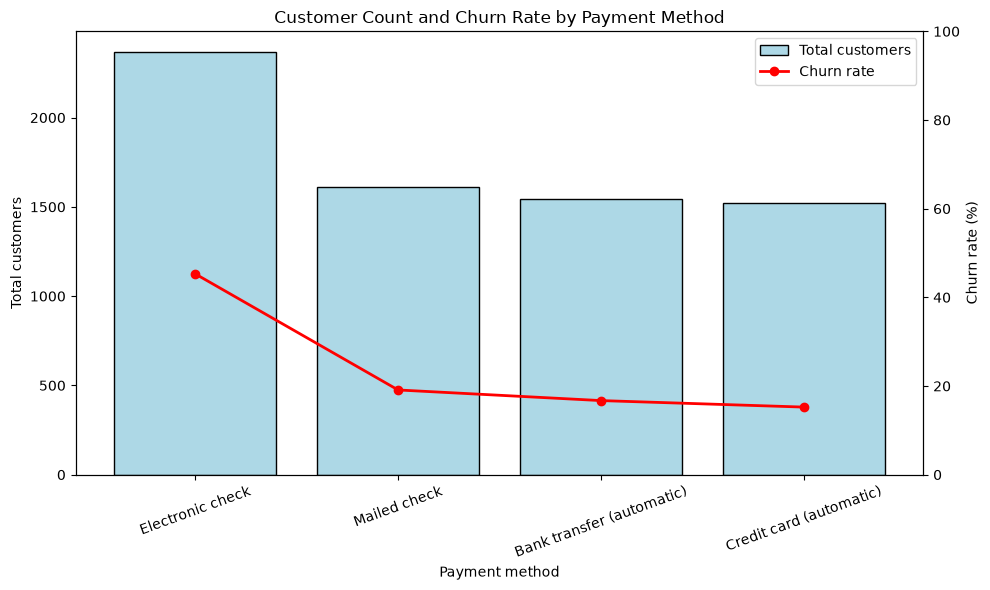

In [414]:

import matplotlib.pyplot as plt
import pandas as pd

# Keep rows with valid churn labels and payment methods
eda = df.loc[
    df["Churn"].isin(["Yes", "No"])
    & df["PaymentMethod"].notna()
].copy()

# Aggregate counts and rates using one groupby
summary = (
    eda.assign(Churned=eda["Churn"].eq("Yes"))
    .groupby("PaymentMethod")
    .agg(
        TotalCustomers=("Churned", "size"),
        ChurnedCustomers=("Churned", "sum"),
        ChurnRate=("Churned", "mean"),
    )
    .sort_values("TotalCustomers", ascending=False)
)

print(summary)

# Plot counts and churn rate
fig, ax = plt.subplots(figsize=(10, 6))

x = summary.index
counts = summary["TotalCustomers"]
rates = summary["ChurnRate"] * 100

# Primary axis: customer counts
bars = ax.bar(
    x, counts,
    color="lightblue",
    edgecolor="black",
    label="Total customers"
)
ax.set_ylabel("Total customers")
ax.set_xlabel("Payment method")
ax.tick_params(axis="x", rotation=20)

# Secondary axis: within-category churn rate
ax2 = ax.twinx()
ax2.plot(
    x, rates,
    color="red",
    marker="o",
    linewidth=2,
    label="Churn rate"
)
ax2.set_ylabel("Churn rate (%)")
ax2.set_ylim(0, 100)

# Combined legend
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")

ax.set_title("Customer Count and Churn Rate by Payment Method")
fig.tight_layout()
plt.show()


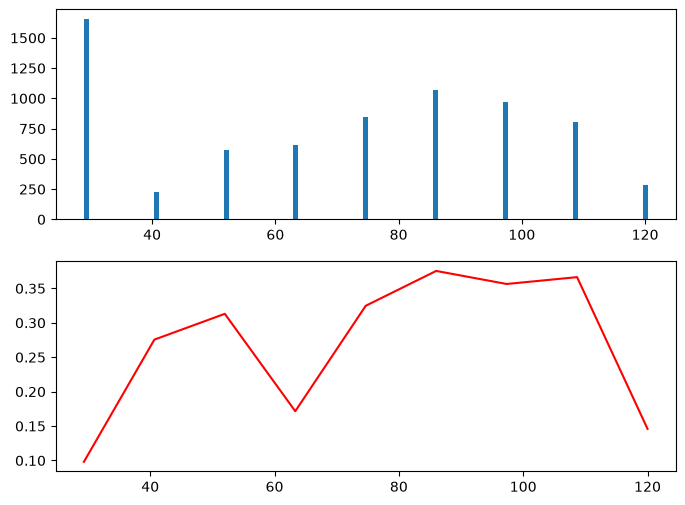

In [415]:
import numpy as np
import matplotlib.pyplot as plt
'''
churning probablity of a customer
with given monthly charges
'''
monthly_charges = df['MonthlyCharges'].copy(deep=True)

# Converting numbers to pure integers
monthly_charges = monthly_charges.astype(int)

# Making bins for the monthly charges
bins = np.linspace(monthly_charges.min(), monthly_charges.max()+2, 10)

churn_stats = [] # stats with each bin collection
bins_element = [] # Indexing with the bins

'''Due to Indexing issues with later layer of collecting ratio we would 
collect ratio paralell to the main execution for the bins values collections
bin rule : low <= value < high
'''

# Loading original values with Integer type also
df['MonthlyCharges'] = df['MonthlyCharges'].astype(int)

prev = bins[0]
for _ in bins[1:]:
    max = _
    user_selection = df[
        ( prev <= df['MonthlyCharges']) & (df['MonthlyCharges'] < max)
    ]
    # Total churned customer with given range
    churned_customer = len(user_selection[
        user_selection['Churn'].eq('Yes')
    ])
    total_customer = len(user_selection)
    probability_of_churning = churned_customer / total_customer

    # prev updating and appending dataset
    prev = _
    churn_stats.append(probability_of_churning) 
    bins_element.append(total_customer)

X = bins[1:]
y = bins_element

# Final Plot
fig, ax = plt.subplots(2,1,figsize=(8,6))

ax[0].bar(X,y)

ax[1].plot(X, churn_stats, color='red')

In [416]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70,151.65,Yes


In [417]:
check = {'Yes':1, 'No':0}

selected_feature_set = [
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges",
    "PaperlessBilling",
    "Churn"
]
# Making simple encoding with 0 and 1 for the binary datasets

train_df = df.loc[:,selected_feature_set].copy(deep=True)

# Cleaning with just removing the Null values
train_df.dropna()

# Must required data conversions
train_df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

# Encoding with charactor rules of occurances across all of the given units
train_df['PaymentMethod'] = train_df['PaymentMethod'].astype('category').cat.codes

train_df['PaperlessBilling'] = train_df['PaperlessBilling'].astype('category').cat.codes
train_df['Churn'] = train_df['Churn'].map(check)

# Fixing total charges filling with mean
train_df['TotalCharges'] = train_df['TotalCharges'].fillna(
    train_df['TotalCharges'].mean()
)



train_df.isna().sum()  # Final Pure Numbers Based feature set for nural network training :)

PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
PaperlessBilling    0
Churn               0
dtype: int64

In [418]:
# Loading dataset with torch to the main frame
import torch
from sklearn.model_selection import train_test_split

# Numpy conversion load
X = (train_df.iloc[:,:-1].copy(deep=True)).values
y = (train_df.iloc[:,-1].copy(deep=True)).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Loading into tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

# Targets
y_train_tensor = torch.tensor(y_train, dtype=torch.int64)
y_test_tensor = torch.tensor(y_test, dtype=torch.int64)

In [419]:
# Wrap into tensor Dataset
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Loading dataset
batch_size = 2 

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### Import glimpse introduction to build nural network
1. torch.nn | nural netowrk library loads with relu and layers options
2. torch.nn.functional | Function style for the layes to work with | handy for quick operations
3. optim.scheduler | validation loop stops improving it automatically decreases learning rate to improve learning
4. reporting with sklearn reports
5. optims load with optimizers requried for the task


In [420]:
# Training Nural Network
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

import torch.optim as optim

In [421]:
# Nural Network implementation
class ChurnPredictor(nn.Module):

    def __init__(self,
                 input_size,
                 hidden_size=[256, 128, 64],
                 dropout_rate=0.2):
        '''
        Parameters
        dropout : regularization technique
        input_size : Initiating config
        hidden_layer : internal config about nodes 

        Initiating super class starts the internal engines of pytorch
        ignites setup for the foundations for the model building

        Training, Testing modes enabling
        and all initiation tasks
        Saving and loading for models, 
        Without initiating, layes wont be registered along with other functions
        '''
        super(ChurnPredictor, self).__init__()

        layers = [] # Keeping things dynamic with layering
        prev_size = input_size # Initiating with the input size 

        for i, hidden_size in enumerate(hidden_size):
            # Linear Layer
            layers.append(
                nn.Linear(
                    prev_size, hidden_size
                )
            )

            # Batch Normalization
            layers.append(nn.BatchNorm1d(hidden_size))

            # Activation
            layers.append(nn.ReLU()) # Non Linear activation function

            # Drop out
            layers.append(nn.Dropout(dropout_rate))

            prev_size = hidden_size

        layers.append(nn.Linear(prev_size, 1))

        # With Sequential function python list is made into proper sequential steps fro making model
        self.network = nn.Sequential(*layers)  # star based unpacking
        self._initialize_weights()

    def _initialize_weights(self):
        '''
        Initializing Linear layers only in our construction sequence
        batch norm and dropout dont need initialization

        We apply initialization to those Linear layers
        with init._contant_ we initiate bias to be zero to avoid arbitrary initiating with non-zero bias
        '''
        for module in self.modules():
            # Xavier/Glroot initiatlization
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                nn.init.constant_(module.bias, 0)

    def forward(self, x):
        ''' 
        Defines how input data flows through the model
        working : network is the sequence we made
        simply feeds input x through the sequence we have...

        We are overriding the weights initiallization through custom weights initiating
        '''
        return self.network(x)

In [422]:
# Training and validation setup
from rich import print

input_size = X_train_tensor.shape[1]

model = ChurnPredictor(input_size=input_size,
                       hidden_size=[256,128,64]).to('cuda')

print(f'''
{'-'*10} MODEL BUILD PRINT {'-'*10}
Total Parameters : {
    sum(p.numel() for p in model.parameters())
}

## Model Architechture
{model}
''')

y = y_train.reshape(-1)

positive = (y == 1).sum().item()
negative = (y == 0).sum().item()

print("Churners:", positive)
print("Non-churners:", negative)
print("Negative / positive:", negative / positive)

# Initiating weights
pos_weight_tensor = torch.tensor(
    negative / positive,
    dtype=torch.float32,
    device="cuda"
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

optimizer = optim.Adam(
    model.parameters(), lr=0.001, weight_decay=1e-5
)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

---------- MODEL BUILD PRINT ----------
Total Parameters : 43393

## Model Architechture
ChurnPredictor(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Churners: 1496

Non-churners: 4138

Negative / positive: 2.766042780748663

In [423]:
# Loading Core tensors
from sklearn.model_selection import train_test_split

X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train_tensor.cpu().numpy(),
    y_train_tensor.cpu().numpy(),
    test_size=0.2, random_state=42, stratify=y_train_tensor.cpu().numpy()
)

# Make sure the validation set and training set never leaks dataset
X_train_split_tensor = torch.FloatTensor(X_train_split).to('cuda')
X_val_split_tensor = torch.FloatTensor(X_val_split).to('cuda')
y_train_split_tensor = torch.FloatTensor(y_train_split).to('cuda')
y_val_split_tensor = torch.FloatTensor(y_val_split).to('cuda')

X_train_split_tensor.shape

torch.Size([4507, 4])

In [424]:
# Training Function

def train_epotch(model, X_train, y_train, optimizer, criterion):
    '''
    One training Epotch
    1. Turning on training mode
    2. optimizers clear out old grads
    3. backward computes gradients
    returns loss  
    '''
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()

In [425]:

def validating_epotch(model, X_val, y_val, criterion):
    model.eval()

    with torch.no_grad():
        logits = model(X_val).reshape(-1)
        targets = y_val.reshape(-1).float()

        loss = criterion(logits, targets)

        probabilities = torch.sigmoid(logits)
        predicted_class = (probabilities >= 0.5).float()

        accuracy = (predicted_class == targets).float().mean()

    return (
        loss.item(),
        accuracy.item(),
        probabilities.cpu().numpy()
    )


In [426]:

num_epochs = 500
best_val_loss = float("inf")

patience_counter = 0
patience_limit = 250

training_loss = []
val_loss = []
val_accuracies = []

for epoch in range(num_epochs):

    train_loss = train_epotch(
        model=model,
        X_train=X_train_split_tensor,
        y_train=y_train_split_tensor,
        optimizer=optimizer,
        criterion=criterion
    )

    validation_loss, val_accuracy, val_predictions = (
        validating_epotch(
            model,
            X_val_split_tensor,
            y_val_split_tensor,
            criterion
        )
    )

    scheduler.step(validation_loss)

    training_loss.append(train_loss)
    val_loss.append(validation_loss)
    val_accuracies.append(val_accuracy)

    current_lr = optimizer.param_groups[0]["lr"]

    if epoch % 10 == 0:
        print(
            f"Epoch: {epoch} | "
            f"LR: {current_lr:.6g} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {validation_loss:.4f} | "
            f"Val accuracy: {val_accuracy:.4f}"
        )

    if validation_loss < best_val_loss:
        best_val_loss = validation_loss
        patience_counter = 0

        torch.save(model.state_dict(), "BestChurnModel.pth")
    else:
        patience_counter += 1

    if patience_counter >= patience_limit:
        print("Early stopping: no validation loss improvement.")
        break

print(f"Best validation loss: {best_val_loss:.4f}")


Epoch: 0 | LR: 0.001 | Train loss: 1.2204 | Val loss: 0.9545 | Val accuracy: 0.6912

Epoch: 10 | LR: 0.001 | Train loss: 0.9251 | Val loss: 0.8913 | Val accuracy: 0.6948

Epoch: 20 | LR: 0.001 | Train loss: 0.8739 | Val loss: 0.8597 | Val accuracy: 0.7143

Epoch: 30 | LR: 0.001 | Train loss: 0.8524 | Val loss: 0.8491 | Val accuracy: 0.7001

Epoch: 40 | LR: 0.001 | Train loss: 0.8375 | Val loss: 0.7982 | Val accuracy: 0.7143

...

Epoch: 460 | LR: 1.52588e-08 | Train loss: 0.8133 | Val loss: 0.7463 | Val accuracy: 0.7427

Epoch: 470 | LR: 1.52588e-08 | Train loss: 0.8148 | Val loss: 0.7464 | Val accuracy: 0.7427

Epoch: 480 | LR: 1.52588e-08 | Train loss: 0.8161 | Val loss: 0.7464 | Val accuracy: 0.7436

Epoch: 490 | LR: 1.52588e-08 | Train loss: 0.8075 | Val loss: 0.7463 | Val accuracy: 0.7436

Best validation loss: 0.7462

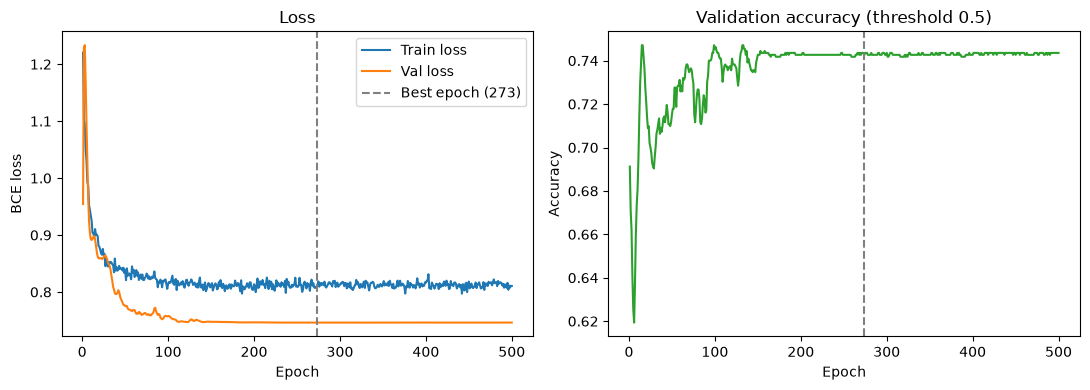

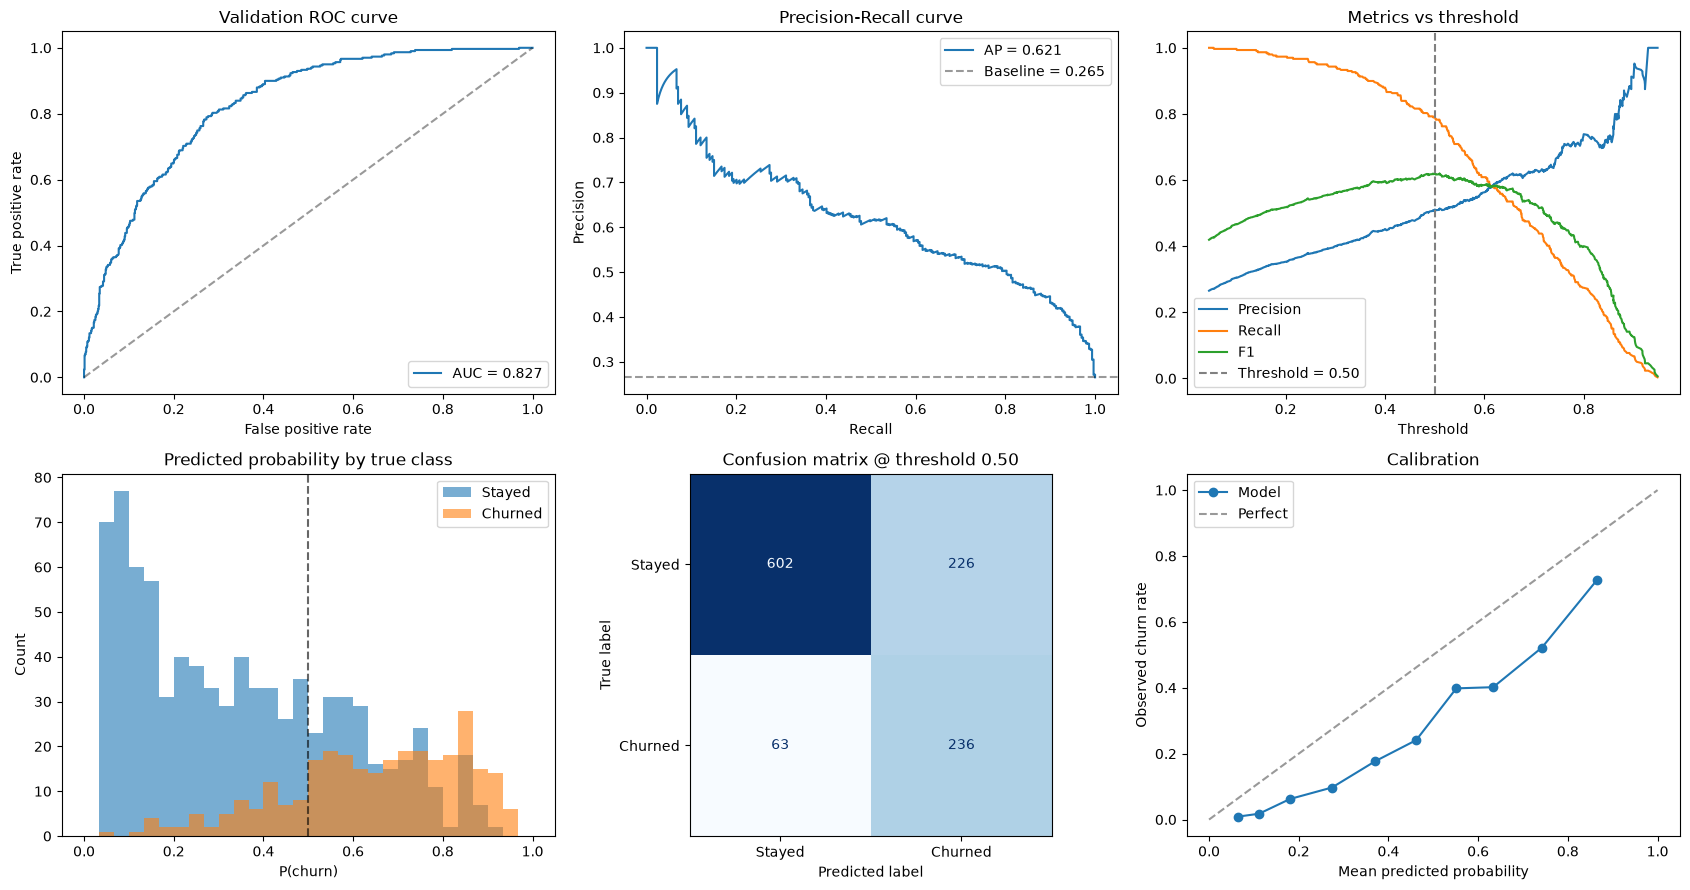

ROC-AUC: 0.8272 | Avg precision: 0.6208 | Threshold: 0.500

precision    recall  f1-score   support

      Stayed      0.905     0.727     0.806       828
     Churned      0.511     0.789     0.620       299

    accuracy                          0.744      1127
   macro avg      0.708     0.758     0.713      1127
weighted avg      0.801     0.744     0.757      1127

In [428]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)
from sklearn.calibration import calibration_curve


def plot_training_curves(training_loss, val_loss, val_accuracies, lrs=None):
    epochs = np.arange(1, len(training_loss) + 1)
    best_epoch = int(np.argmin(val_loss)) + 1
    ncols = 3 if lrs is not None else 2
    fig, ax = plt.subplots(1, ncols, figsize=(5.5 * ncols, 4))

    ax[0].plot(epochs, training_loss, label="Train loss")
    ax[0].plot(epochs, val_loss, label="Val loss")
    ax[0].axvline(best_epoch, color="gray", ls="--", label=f"Best epoch ({best_epoch})")
    ax[0].set(title="Loss", xlabel="Epoch", ylabel="BCE loss")
    ax[0].legend()

    ax[1].plot(epochs, val_accuracies, color="tab:green")
    ax[1].axvline(best_epoch, color="gray", ls="--")
    ax[1].set(title="Validation accuracy (threshold 0.5)", xlabel="Epoch", ylabel="Accuracy")

    if lrs is not None:
        ax[2].plot(epochs, lrs, color="tab:red")
        ax[2].set_yscale("log")
        ax[2].set(title="Learning rate", xlabel="Epoch", ylabel="LR")

    plt.tight_layout()
    plt.show()


def plot_diagnostics(y_true, probs, threshold=None, title_prefix="Validation"):
    """If threshold is None, the best-F1 threshold is found on this data.
    Pass the validation threshold when plotting the test set."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    probs = np.asarray(probs).reshape(-1)

    auc = roc_auc_score(y_true, probs)
    ap = average_precision_score(y_true, probs)

    prec, rec, thr = precision_recall_curve(y_true, probs)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    if threshold is None:
        threshold = float(thr[f1.argmax()])

    fig, ax = plt.subplots(2, 3, figsize=(17, 9))

    fpr, tpr, _ = roc_curve(y_true, probs)
    ax[0, 0].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    ax[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax[0, 0].set(title=f"{title_prefix} ROC curve", xlabel="False positive rate",
                 ylabel="True positive rate")
    ax[0, 0].legend(loc="lower right")

    ax[0, 1].plot(rec, prec, label=f"AP = {ap:.3f}")
    ax[0, 1].axhline(y_true.mean(), color="k", ls="--", alpha=0.4,
                     label=f"Baseline = {y_true.mean():.3f}")
    ax[0, 1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
    ax[0, 1].legend(loc="upper right")

    ax[0, 2].plot(thr, prec[:-1], label="Precision")
    ax[0, 2].plot(thr, rec[:-1], label="Recall")
    ax[0, 2].plot(thr, f1, label="F1")
    ax[0, 2].axvline(threshold, color="gray", ls="--", label=f"Threshold = {threshold:.2f}")
    ax[0, 2].set(title="Metrics vs threshold", xlabel="Threshold")
    ax[0, 2].legend()

    bins = np.linspace(0, 1, 31)
    ax[1, 0].hist(probs[y_true == 0], bins=bins, alpha=0.6, label="Stayed")
    ax[1, 0].hist(probs[y_true == 1], bins=bins, alpha=0.6, label="Churned")
    ax[1, 0].axvline(threshold, color="k", ls="--", alpha=0.6)
    ax[1, 0].set(title="Predicted probability by true class", xlabel="P(churn)", ylabel="Count")
    ax[1, 0].legend()

    pred = (probs >= threshold).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred),
                           display_labels=["Stayed", "Churned"]).plot(
        ax=ax[1, 1], colorbar=False, cmap="Blues")
    ax[1, 1].set_title(f"Confusion matrix @ threshold {threshold:.2f}")

    frac_pos, mean_pred = calibration_curve(y_true, probs, n_bins=10, strategy="quantile")
    ax[1, 2].plot(mean_pred, frac_pos, "o-", label="Model")
    ax[1, 2].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Perfect")
    ax[1, 2].set(title="Calibration", xlabel="Mean predicted probability",
                 ylabel="Observed churn rate")
    ax[1, 2].legend()

    plt.tight_layout()
    plt.show()

    print(f"ROC-AUC: {auc:.4f} | Avg precision: {ap:.4f} | Threshold: {threshold:.3f}\n")
    print(classification_report(y_true, pred, target_names=["Stayed", "Churned"], digits=3))
    return threshold


# ---------------- run ----------------
# Reload the best checkpoint (model currently holds last-epoch weights)
model.load_state_dict(torch.load("BestChurnModel.pth"))

# 1. Training curves (pass lrs=lrs if you added the lrs list)
plot_training_curves(training_loss, val_loss, val_accuracies, lrs=None)

# 2. Validation diagnostics with the best model
_, _, val_probs = validating_epotch(model, X_val_split_tensor, y_val_split_tensor, criterion)
best_thr = plot_diagnostics(y_val_split, val_probs, title_prefix="Validation")

# 3. Later, on a held-out test set, reuse the validation threshold:
# _, _, test_probs = validating_epotch(model, X_test_tensor, y_test_tensor, criterion)
# plot_diagnostics(y_test, test_probs, threshold=best_thr, title_prefix="Test")